## Analysis of Algorithms

In [2]:
## Assessing Insertion-Sort, Quick-Sort, and Merge-Sort

In [2]:
import time
import random
import numpy as np
import matplotlib.pyplot as plt
import sys


sys.setrecursionlimit(1000000)

In [3]:
# Insertion Sort
def insertion_sort(arr):
    a = arr.copy()
    for i in range(1, len(a)):
        key = a[i]
        j = i - 1
        while j >= 0 and a[j] > key:
            a[j + 1] = a[j]
            j -= 1
        a[j + 1] = key
    return a

# Merge Sort
def merge_sort(arr):
    if len(arr) <= 1:
        return arr
    mid = len(arr) // 2
    left = merge_sort(arr[:mid])
    right = merge_sort(arr[mid:])
    return merge(left, right)

def merge(left, right):
    result = []
    i = j = 0
    while i < len(left) and j < len(right):
        if left[i] <= right[j]:
            result.append(left[i])
            i += 1
        else:
            result.append(right[j])
            j += 1
    result.extend(left[i:])
    result.extend(right[j:])
    return result

# Quick Sort
def quick_sort(arr):
    a = arr.copy()
    _quick_sort(a, 0, len(a)-1)
    return a

def _quick_sort(arr, low, high):
    if low < high:
        p = partition(arr, low, high)
        _quick_sort(arr, low, p-1)
        _quick_sort(arr, p+1, high)

def partition(arr, low, high):
    pivot = arr[high]
    i = low - 1
    for j in range(low, high):
        if arr[j] <= pivot:
            i += 1
            arr[i], arr[j] = arr[j], arr[i] # I understand till here but don't have clue afterwards
    arr[i+1], arr[high] = arr[high], arr[i+1]
    return i + 1


In [4]:
def generate_list(list_type, n):
    if list_type == 'random':
        return [random.randint(0, n) for _ in range(n)]
    elif list_type == 'ascending':
        return list(range(n))
    elif list_type == 'descending':
        return list(range(n, 0, -1))
    elif list_type == 'nearly_sorted':
        lst = list(range(n))
        # 10% perturbations
        num_swaps = max(1, n // 10)
        for _ in range(num_swaps):
            i, j = random.randint(0, n-1), random.randint(0, n-1)
            lst[i], lst[j] = lst[j], lst[i]
        return lst
    elif list_type == 'many_duplicates':
        return [random.randint(0, max(1, n//10)) for _ in range(n)]


In [5]:
def time_algorithm(algorithm, list_type, n, runs=10):
    times = []
    for _ in range(runs):
        lst = generate_list(list_type, n)
        start = time.perf_counter_ns()
        algorithm(lst)
        end = time.perf_counter_ns()
        times.append((end - start)/1e6)  # convert ns to ms
    return np.mean(times), np.std(times)


In [6]:
list_types = ['random', 'ascending', 'descending', 'nearly_sorted', 'many_duplicates']
algorithms = {'Insertion Sort': insertion_sort, 
              'Merge Sort': merge_sort, 
              'Quick Sort': quick_sort}

list_sizes = [10, 50, 100, 500, 1000, 5000, 10000, 20000, 50000]

results = {alg: {lt: [] for lt in list_types} for alg in algorithms}

for alg_name, alg_func in algorithms.items():
    print(f"Timing {alg_name}...")
    for lt in list_types:
        for n in list_sizes:
            mean_time, std_time = time_algorithm(alg_func, lt, n)
            results[alg_name][lt].append((n, mean_time, std_time))
            print(f"{lt} n={n} -> {mean_time:.2f}ms ± {std_time:.2f}ms")


Timing Insertion Sort...
random n=10 -> 0.01ms ± 0.00ms
random n=50 -> 0.14ms ± 0.02ms
random n=100 -> 0.35ms ± 0.07ms
random n=500 -> 4.82ms ± 1.67ms
random n=1000 -> 9.98ms ± 1.37ms
random n=5000 -> 236.34ms ± 3.80ms
random n=10000 -> 985.47ms ± 17.63ms
random n=20000 -> 4032.44ms ± 64.21ms
random n=50000 -> 26905.07ms ± 595.69ms
ascending n=10 -> 0.00ms ± 0.00ms
ascending n=50 -> 0.00ms ± 0.00ms
ascending n=100 -> 0.00ms ± 0.00ms
ascending n=500 -> 0.02ms ± 0.00ms
ascending n=1000 -> 0.05ms ± 0.00ms
ascending n=5000 -> 0.26ms ± 0.01ms
ascending n=10000 -> 0.57ms ± 0.07ms
ascending n=20000 -> 1.04ms ± 0.05ms
ascending n=50000 -> 2.64ms ± 0.07ms
descending n=10 -> 0.00ms ± 0.00ms
descending n=50 -> 0.05ms ± 0.00ms
descending n=100 -> 0.20ms ± 0.02ms
descending n=500 -> 4.62ms ± 0.14ms
descending n=1000 -> 19.22ms ± 0.30ms
descending n=5000 -> 500.95ms ± 5.16ms
descending n=10000 -> 2029.12ms ± 28.65ms
descending n=20000 -> 7975.59ms ± 121.04ms
descending n=50000 -> 49826.73ms ± 561.75

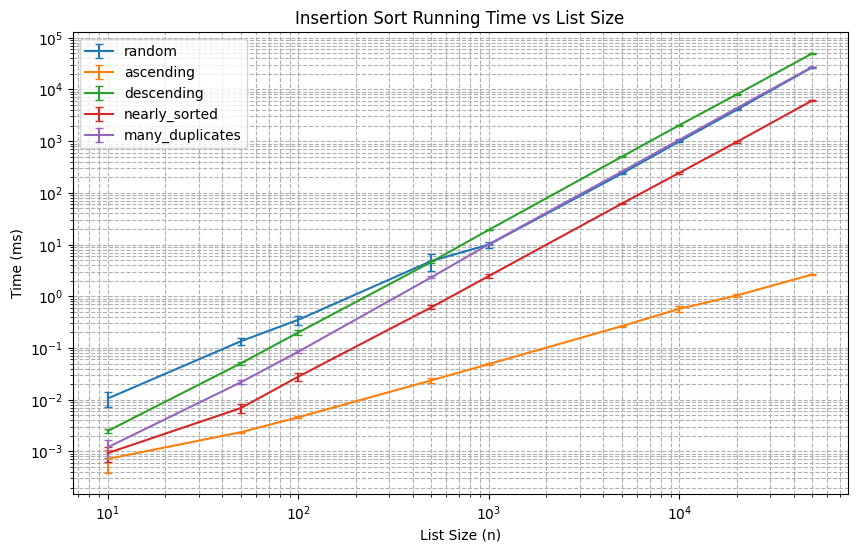

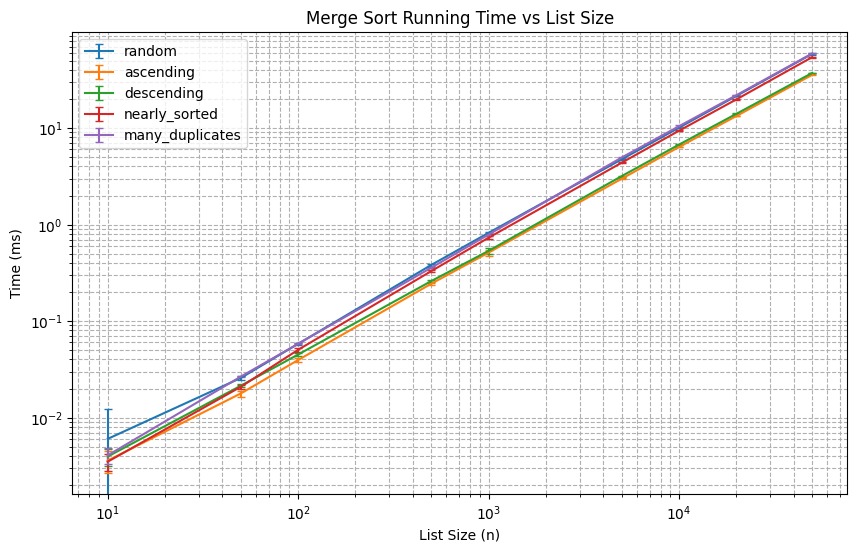

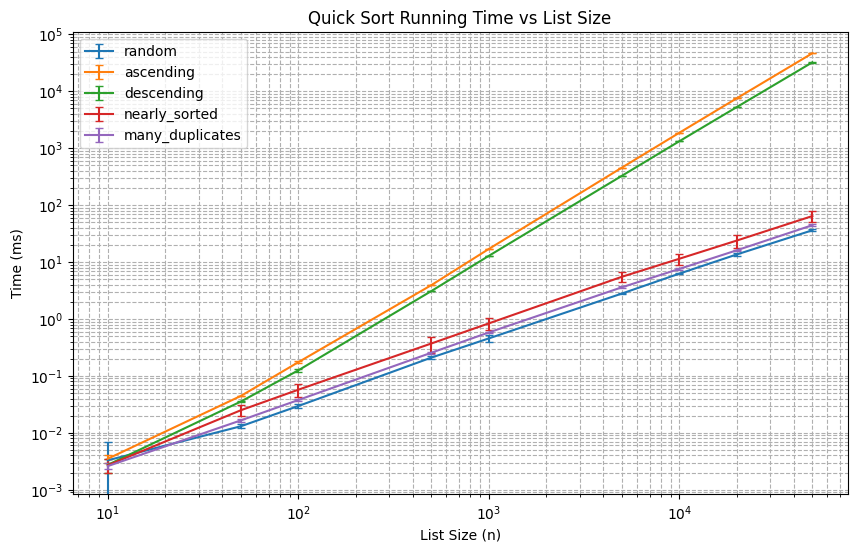

In [7]:
for alg_name in algorithms:
    plt.figure(figsize=(10,6))
    for lt in list_types:
        data = results[alg_name][lt]
        ns = [x[0] for x in data]
        means = [x[1] for x in data]
        stds = [x[2] for x in data]
        plt.errorbar(ns, means, yerr=stds, label=lt, capsize=3)
    plt.title(f"{alg_name} Running Time vs List Size")
    plt.xlabel("List Size (n)")
    plt.ylabel("Time (ms)")
    plt.xscale('log')
    plt.yscale('log')
    plt.legend()
    plt.grid(True, which="both", ls="--")
    plt.show()


## Reflection
#### Insertion Sort
fast on small, nearly sorted lists, and already sorted lists. 
very slow for large random or descending data
Random order is better than descending orders at higher data numbers
Worst case: 0(n2) when the list is descending order
Average case: 0(n2) when the list is random
Best case: 0(n) when the list is sorted
#### Merge Sort
Good performance and stable
Not that much sensitive to ordering, the graph shows clearly about that
The time complexity is the same nlgn for all data orders even if it is sorted
#### Quick Sort
Fast for random, nearly sorted, and lists with many duplicates
worst case for ascending order since I used Lamuto Algorithm (Pivot is the last element)
pivot selection matters
Worst case: 0(n2) when the list is ordered in ascending or descending manners
Average case: 0(nlgn) for random arrays
Lamuto swaps in place so no need for extra arrays. When the recursion limit exceeds, I raised the limit.